# Cosine Similarity

Cosine similarity is a metric used to measure how similar two non-zero vectors are. It measures the cosine of the angle between two vectors. A cosine similarity of 1 means the vectors are identical (point in the same direction), 0 means they are orthogonal (no similarity), and -1 means they are exactly opposite. It's often used in natural language processing to compare the similarity of documents or sentences.

# Mathematical Formula:


Cosine similarity between two vectors A and B is calculated as:

* cos(θ)= (A . B) / (||A|| * ||B||)

#What problem cosine similarity is solving


In text data, recommender systems, and ML features, we often want to answer:

“How similar are two vectors in direction, not in size?”

Examples:

* Two documents with same topic but different lengths

* Two users with similar preferences but different activity levels

* Two feature vectors scaled differently

#Why dot product alone is NOT enough



Consider two document vectors:

Document 1: short article

Document 2: long article on same topic

Their vectors point in same direction, but:

* Longer document → larger magnitude

* Dot product becomes large just because of length

*  Dot product incorrectly says they are “more similar” than they actually are.

#Why we divide by magnitudes (normalization)


# Cosine Similarity Explained and Implemented

This notebook provides a comprehensive explanation and practical implementation of Cosine Similarity, a fundamental metric in natural language processing (NLP) and information retrieval.

## Table of Contents

1.  [Introduction to Cosine Similarity](#introduction-to-cosine-similarity)
2.  [Mathematical Formula](#mathematical-formula)
3.  [Why Cosine Similarity?](#why-cosine-similarity)
4.  [Implementation Details](#implementation-details)
5.  [Observational Notes](#observational-notes)
6.  [How to Run](#how-to-run)
7.  [Dependencies](#dependencies)

## Introduction to Cosine Similarity

Cosine similarity measures the similarity between two non-zero vectors in an inner product space. It is defined as the cosine of the angle between them, which determines whether two vectors are pointing in roughly the same direction. The value ranges from -1 to 1, where 1 means identical direction, 0 means orthogonality (no similarity), and -1 means exactly opposite direction. In contexts like TF-IDF where values are non-negative, the range typically becomes 0 to 1.

## Mathematical Formula

Cosine similarity between two vectors A and B is calculated as:

$ \cos(\theta) = \frac{A \cdot B}{||A|| \cdot ||B||} $

Where:
*   $ A \cdot B $ is the dot product of vectors A and B.
*   $ ||A|| $ and $ ||B|| $ are the magnitudes (Euclidean norms) of vectors A and B, respectively.

## Why Cosine Similarity?

This notebook addresses why cosine similarity is a preferred metric in various domains, especially when the magnitude of vectors is not relevant to their similarity. Key points include:

*   **Direction over Magnitude**: Focuses on the angle between vectors, ignoring their length. This is crucial for comparing documents of different lengths that might discuss the same topic.
*   **Normalization**: Division by magnitudes normalizes vectors, transforming them into unit vectors and removing size bias.
*   **Interpretable Range**: Provides a clear and stable similarity score between 0 and 1 (for non-negative vectors).
*   **NLP Applications**: Ideal for comparing text data where dimensions represent words (e.g., TF-IDF scores). It effectively identifies semantic similarity regardless of document size.

## Implementation Details

The notebook demonstrates the calculation of cosine similarity using Python's `scikit-learn` library. The process involves:

1.  **TF-IDF Vectorization**: Converting a collection of raw documents (sentences) into a matrix of TF-IDF features. This assigns a weight to each term based on its frequency in a document and its rarity across all documents.
    *   `TfidfVectorizer` is used to create a vocabulary and transform the text data into numerical vectors.

2.  **Bag-of-TFIDF-Vectors Representation**: Visualizing the TF-IDF representation of sentences and a query.
    *   A Pandas DataFrame is used to display the TF-IDF scores for each word in each sentence and the query.

3.  **Step-by-Step Calculation**: Breaking down the cosine similarity calculation into its core components:
    *   **Dot Product**: Calculation of the dot product between the query vector and each sentence vector. A higher dot product indicates more shared important words.
    *   **Vector Magnitudes**: Calculation of the magnitude (length) of the query vector and each sentence vector. This helps in normalizing the vectors.
    *   **Cosine Similarity**: Final calculation of cosine similarity using the dot product and magnitudes. The results show how similar each sentence is to the given query.

## Observational Notes

The notebook includes observational notes on:

*   **Vocabulary**: How TF-IDF vectorization extracts unique, meaningful words, excluding common stop-words.
*   **TF-IDF Values**: Explanation of how TF-IDF scores are derived, weighting informative words higher than common ones.
*   **Dot Product**: Interpretation of the dot product as a measure of semantic overlap.
*   **Magnitude**: The role of vector magnitude in normalizing similarity scores.
*   **Cosine Similarity**: How the final cosine similarity score reflects semantic similarity.

## How to Run

To run this notebook:

1.  Open it in Google Colab or any Jupyter environment.
2.  Execute each code cell sequentially.
3.  Observe the output which includes vocabulary, TF-IDF representations, dot products, magnitudes, and the final cosine similarity scores for each sentence against the query.

## Dependencies

*   `numpy`
*   `pandas`
*   `scikit-learn` (`sklearn.feature_extraction.text.TfidfVectorizer`, `sklearn.metrics.pairwise.cosine_similarity`)

These dependencies can be installed using pip:

```bash
pip install numpy pandas scikit-learn
```


To remove the effect of length, we divide by:

* ∥ 𝐴 ∥ ∥ 𝐵 ∥ ∥A∥∥B∥

* This normalizes the dot product.

 What normalization does:

* Converts vectors into unit vectors

* Keeps only direction

* Removes scale / size bias

# Why angle represents similarity

 * Angle measures orientation

* Orientation represents pattern similarity

Pattern similarity is what matters in:

* NLP

* Information retrieval

* Recommendation systems

| Angle (θ) | Cosine value | Meaning             |
| --------- | ------------ | ------------------- |
| 0°        | 1            | Identical direction |
| 90°       | 0            | No similarity       |
| 180°      | −1           | Opposite meaning    |


# Why cosine similarity range is ideal

−1≤cos(θ)≤1

But in TF-IDF / word counts:

* Values are non-negative

* So range becomes 0 to 1

This makes cosine similarity:

* Interpretable

* Comparable

* Stable across datasets

# Why cosine similarity is perfect for NLP

In text:

* Each dimension = word

* Value = TF or TF-IDF score

* Document length varies heavily

Cosine similarity ensures:

* Same topic → high similarity

* Different topic → low similarity

* Document size doesn’t matter

That’s why cosine similarity is standard in:

* Search engines

* Document clustering

* Spam detection

* Sentiment analysis

# Mathematical breakdown (step-by-step)

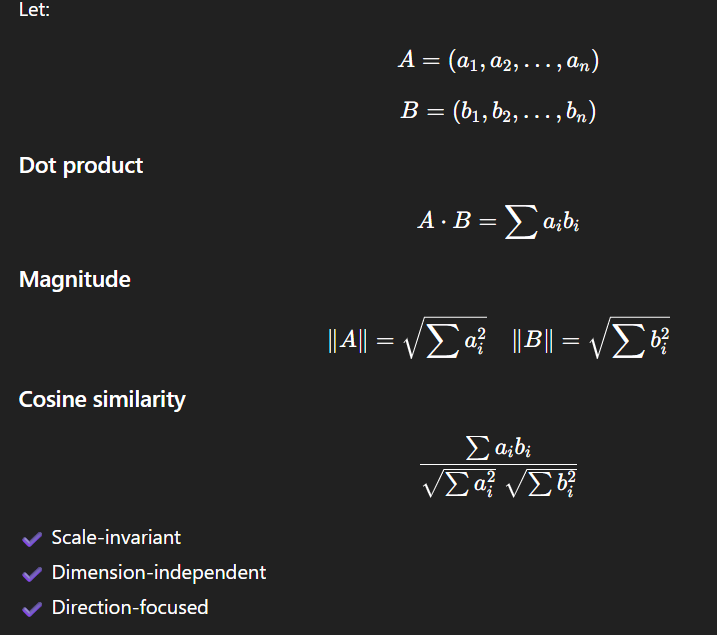

# code

In [1]:
  from sklearn.feature_extraction.text import TfidfVectorizer
  from sklearn.metrics.pairwise import cosine_similarity
  import pandas as pd


In [2]:
sentences = [
    "I feel stress at job every day",
    "My job pressure is very high due to stress",
    "I havve  stress and anxiety",
    "Mental stress affects health",
    "Work life balance is important",
    "Exercise reduces anxiety and stress"
]
query = ["stress at job "]

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

all_text = sentences + query
tfidf = vectorizer.fit_transform(all_text)
vocab = vectorizer.get_feature_names_out()
print("Vocabulary:\n", vocab)
for i, sentence in enumerate(sentences):
    print(f"\nSentence {i+1}: {sentence}")
    print("Words used:", sentence.lower().split())



Vocabulary:
 ['affects' 'and' 'anxiety' 'at' 'balance' 'day' 'due' 'every' 'exercise'
 'feel' 'havve' 'health' 'high' 'important' 'is' 'job' 'life' 'mental'
 'my' 'pressure' 'reduces' 'stress' 'to' 'very' 'work']

Sentence 1: I feel stress at job every day
Words used: ['i', 'feel', 'stress', 'at', 'job', 'every', 'day']

Sentence 2: My job pressure is very high due to stress
Words used: ['my', 'job', 'pressure', 'is', 'very', 'high', 'due', 'to', 'stress']

Sentence 3: I havve  stress and anxiety
Words used: ['i', 'havve', 'stress', 'and', 'anxiety']

Sentence 4: Mental stress affects health
Words used: ['mental', 'stress', 'affects', 'health']

Sentence 5: Work life balance is important
Words used: ['work', 'life', 'balance', 'is', 'important']

Sentence 6: Exercise reduces anxiety and stress
Words used: ['exercise', 'reduces', 'anxiety', 'and', 'stress']


📌 Observational Note (Vocabulary)

From the constructed TF-IDF vocabulary, it is observed that the vocabulary consists of all unique, meaningful words extracted from the complete corpus of sentences and the query. Common stop-words such as “i” are excluded automatically by the TF-IDF vectorizer, while content-bearing words like stress, job, work, and health are retained.

Considering Sentence 1: “I feel stress at job every day”, the words extracted from this sentence are:

['i', 'feel', 'stress', 'at', 'job', 'every', 'day']


Out of these words, only the terms feel, stress, at, job, every, and day appear in the final vocabulary. The word “i” does not contribute to the TF-IDF representation because it is a common pronoun with low informational value.

so the voacb will be : [ 'at','day','evey','feel','job','stress']

In [4]:
tfidf_matrix = vectorizer.fit_transform(sentences + query)

sentence_vectors = tfidf_matrix[:-1]
query_vector = tfidf_matrix[-1]

tfidf_df = pd.DataFrame(
    sentence_vectors.toarray(),
    columns=vocab,
    index=sentences
)

sentence_bow = []

for sentence in sentences:
    row = tfidf_df.loc[sentence]
    bow = row[row > 0]

    sentence_bow.append({
        "Sentence": sentence,
        "Bag_of_TFIDF_Vectors": bow.to_dict()
    })


query_row = pd.Series(
    query_vector.toarray()[0],
    index=vocab
)

query_bow = query_row[query_row > 0]

sentence_bow.append({

    "Bag_of_TFIDF_Vectors": query_bow.to_dict()
})

final_df = pd.DataFrame(sentence_bow)

final_df.style.set_properties(
    **{
        'text-align': 'left',
        'font-family': 'monospace',
        'white-space': 'pre',
    }
)


,Sentence,Bag_of_TFIDF_Vectors
0,I feel stress at job every day,"{'at': 0.3949157279638881, 'day': 0.47575285619643665, 'every': 0.47575285619643665, 'feel': 0.47575285619643665, 'job': 0.33756087272246943, 'stress': 0.2259908946758588}"
1,My job pressure is very high due to stress,"{'due': 0.3671581449068448, 'high': 0.3671581449068448, 'is': 0.3047727915560611, 'job': 0.2605096789387298, 'my': 0.3671581449068448, 'pressure': 0.3671581449068448, 'stress': 0.1744065150094793, 'to': 0.3671581449068448, 'very': 0.3671581449068448}"
2,I havve stress and anxiety,"{'and': 0.5144288648991059, 'anxiety': 0.5144288648991059, 'havve': 0.6197296902999521, 'stress': 0.29438239906278474}"
3,Mental stress affects health,"{'affects': 0.5567906678918844, 'health': 0.5567906678918844, 'mental': 0.5567906678918844, 'stress': 0.26448526697252517}"
4,Work life balance is important,"{'balance': 0.4618042361109319, 'important': 0.4618042361109319, 'is': 0.38333717539523177, 'life': 0.4618042361109319, 'work': 0.4618042361109319}"
5,Exercise reduces anxiety and stress,"{'and': 0.4372674031382019, 'anxiety': 0.4372674031382019, 'exercise': 0.5267736917877859, 'reduces': 0.5267736917877859, 'stress': 0.250226680404149}"
6,nan,"{'at': 0.6970549689351914, 'job': 0.5958194799241149, 'stress': 0.39889035790015837}"


📌 Observational Note (Tf-idf)
Term Frequency (TF) represents how often a word appears in a sentence, while Inverse Document Frequency (IDF) reduces the weight of common words that appear in many sentences. This combination ensures that common words like “is” or “the” get low scores, whereas informative words such as “stress”, “job”, or “health” get higher scores

[ 'at','day','evey','feel','job','stress'] = ['0.394','0.4757','0.4757','0.475','0.337','0.225']

Query : ['at','job','stress']:['0.697','0.598','0.398']

In [5]:
import numpy as np

query_array = query_vector.toarray()[0]

for i in range(len(sentences)):
    sentence_array = sentence_vectors[i].toarray()[0]
    dot = np.dot(query_array, sentence_array)
    print(f"Dot product with sentence {i+1}: {dot}")


Dot product with sentence 1: 0.5665489029755489
Dot product with sentence 2: 0.22478581861272268
Dot product with sentence 3: 0.11742630052166145
Dot product with sentence 4: 0.1055006228019895
Dot product with sentence 5: 0.0
Dot product with sentence 6: 0.09981301010257955


The dot product measures the overlap of common important words between the sentence and the query. It is calculated by multiplying the TF-IDF values of corresponding common terms and summing them. A higher dot product indicates greater semantic overlap.
Common words between sentence and query:

[at, job, stress]

S′=[0.394,0.337,0.225]

Query𝑄=[0.697,  0.598, 0.398]

S′*Q=(0.394×0.697)+(0.337×0.598)+(0.225×0.398)

=0.2746
+
0.2015
+
0.0896

=0.2746+0.2015+0.0896
=0.5665

In [6]:
query_mag = np.sqrt(np.sum(query_array ** 2))
print("Query magnitude:", query_mag)

for i in range(len(sentences)):
    sentence_array = sentence_vectors[i].toarray()[0]
    sent_mag = np.sqrt(np.sum(sentence_array ** 2))
    print(f"Magnitude of sentence {i+1}:", sent_mag)


Query magnitude: 0.9999999999999999
Magnitude of sentence 1: 1.0
Magnitude of sentence 2: 0.9999999999999999
Magnitude of sentence 3: 1.0
Magnitude of sentence 4: 0.9999999999999999
Magnitude of sentence 5: 1.0
Magnitude of sentence 6: 1.0


Magnitude represents the length of a vector in the TF-IDF space. It is calculated as the square root of the sum of squared TF-IDF values. Magnitude is used to normalize vectors so that longer sentences do not get unfairly higher similarity scores.

∣∣S′∣∣= 1.00

∣∣Q∣∣=0.99

In [7]:
for i in range(len(sentences)):
    sentence_array = sentence_vectors[i].toarray()[0]

    dot = np.dot(query_array, sentence_array)
    sent_mag = np.sqrt(np.sum(sentence_array ** 2))

    cosine_sim = dot / (query_mag * sent_mag)

    print(f"\nSentence: {sentences[i]}")
    print("Cosine Similarity:", cosine_sim)



Sentence: I feel stress at job every day
Cosine Similarity: 0.566548902975549

Sentence: My job pressure is very high due to stress
Cosine Similarity: 0.22478581861272273

Sentence: I havve  stress and anxiety
Cosine Similarity: 0.11742630052166146

Sentence: Mental stress affects health
Cosine Similarity: 0.10550062280198953

Sentence: Work life balance is important
Cosine Similarity: 0.0

Sentence: Exercise reduces anxiety and stress
Cosine Similarity: 0.09981301010257956


Cosine similarity measures the angle between two vectors, not their absolute size. It is computed as the dot product divided by the product of their magnitudes. The value lies between 0 and 1, where values closer to 1 indicate higher semantic similarity.

Cosine Similarity=S′⋅Q ​/ ∣∣S′∣∣×∣∣Q∣∣

=0.5667/1×0.99
=0.5665